## Retrieval Augmented Generation (RAG) Pipeline

Retrieval Augmented Generation (RAG) is an architectural pattern that enhances the capabilities of large language models (LLMs) by providing them with access to external knowledge sources. Instead of relying solely on the information they learned during training, RAG models can retrieve relevant information from a separate knowledge base (like documents, databases, or websites) at inference time and then use this information to generate more accurate, up-to-date, and context-specific responses.

### Why RAG?

*   **Reduces Hallucinations:** LLMs can sometimes generate incorrect or fabricated information. RAG grounds their responses in factual data.
*   **Access to Up-to-Date Information:** LLMs' knowledge is limited to their training data. RAG allows them to access the latest information not present in their training set.
*   **Domain-Specific Knowledge:** Enables LLMs to answer questions about specific, private, or proprietary data that they were not trained on.
*   **Transparency and Explainability:** By showing the retrieved documents, RAG can provide insight into *why* an LLM generated a particular answer.

Let's build a basic RAG pipeline step-by-step.

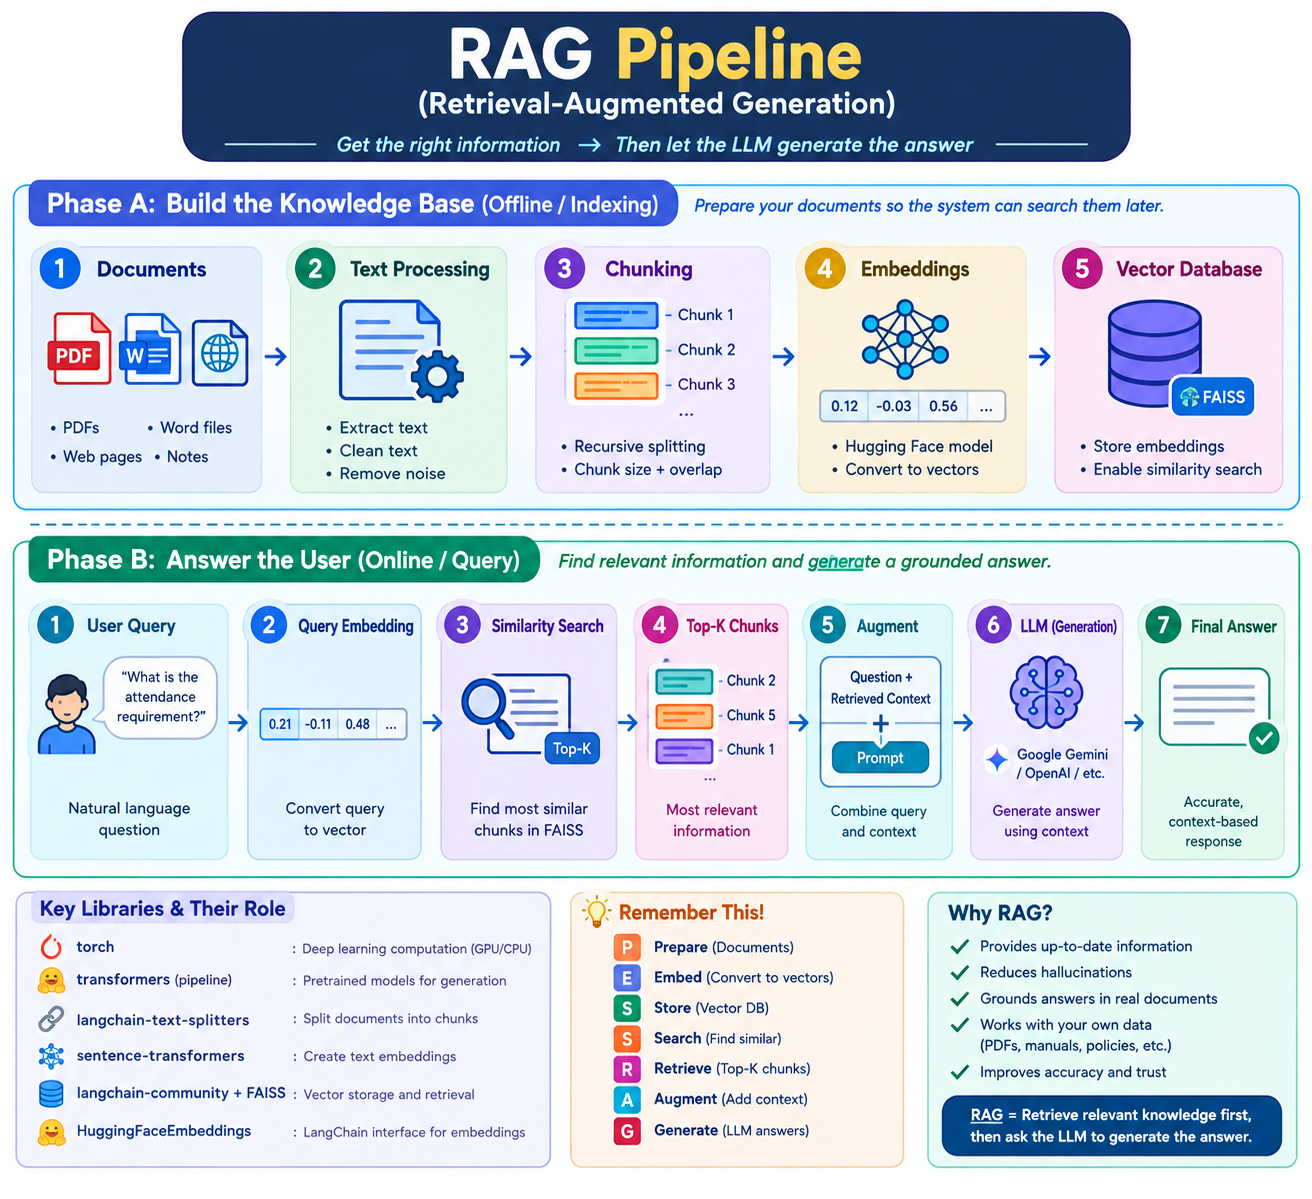

### 1. Setup and Installations

First, we need to install the necessary libraries. We'll use:

*   `transformers`: For models like sentence transformers for embeddings and potentially a small generative model.
*   `faiss-cpu`: A library for efficient similarity search and clustering of dense vectors (our vector database).
*   `sentence-transformers`: For easily creating embeddings from text.
*   `langchain`: A framework that helps build applications with LLMs, especially useful for text splitting and integration with vector stores.

In [ ]:
# Install necessary libraries
!pip install transformers faiss-cpu sentence-transformers langchain langchain-community langchain_text_splitters torch accelerate -qq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 46.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 56.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 6.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


### 2. Prepare Data (Knowledge Base)

For this basic example, we'll use a simple block of text as our knowledge base. In a real-world scenario, this would be a collection of documents, articles, or other textual data.

import torch
from transformers import pipeline
from langchain_text_splitters import RecursiveCharacterTextSplitter
from sentence_transformers import SentenceTransformer
from langchain_community.vectorstores import FAISS
from langchain_community.embeddings import HuggingFaceEmbeddings

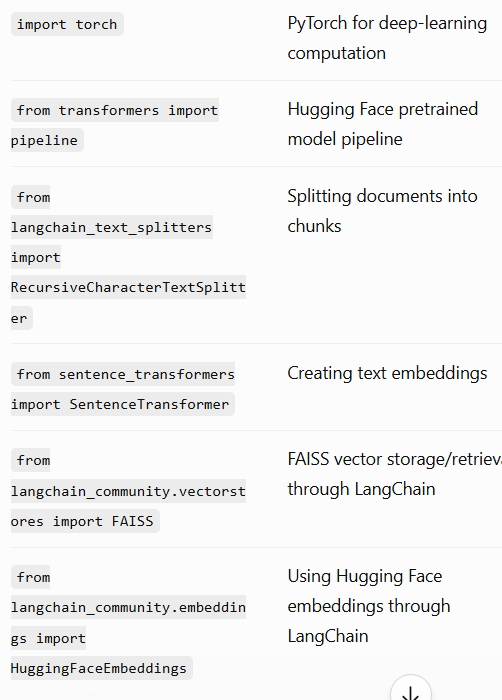

In [ ]:
import torch
from transformers import pipeline
from langchain_text_splitters import RecursiveCharacterTextSplitter
from sentence_transformers import SentenceTransformer
from langchain_community.vectorstores import FAISS
from langchain_community.embeddings import HuggingFaceEmbeddings

# Our sample knowledge base text
knowledge_base_text = """
The Andromeda Galaxy (M31) is a barred spiral galaxy approximately 2.5 million light-years from Earth and the nearest large galaxy to the Milky Way. It gets its name from the constellation Andromeda, where it appears in the night sky. Andromeda is the largest galaxy of the Local Group, which also contains the Milky Way, the Triangulum Galaxy, and about 30 other smaller galaxies. The galaxy's diameter is about 220,000 light-years, making it larger than the Milky Way. It contains approximately one trillion stars, compared to the Milky Way's 200–400 billion. It is estimated that the Andromeda Galaxy and the Milky Way are on a collision course, expected to merge in about 4.5 billion years. This merger will likely form a giant elliptical galaxy.

The Milky Way is a barred spiral galaxy that is part of the Local Group. It is home to our Solar System. Its diameter is estimated to be between 100,000 and 180,000 light-years. It contains 200–400 billion stars. At its center lies a supermassive black hole called Sagittarius A*."""

print("Knowledge base loaded successfully.")

/tmp/ipykernel_968/2947599096.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


Knowledge base loaded successfully.


### 3. Text Chunking

Large documents need to be broken down into smaller, manageable chunks. This is important because:

*   **Relevance:** It's easier to find specific relevant information within smaller chunks.
*   **Context Window:** LLMs have a limited context window (the amount of text they can process at once). Chunks ensure we stay within this limit.
*   **Efficiency:** Searching through smaller pieces of text is faster.

We'll use `RecursiveCharacterTextSplitter` from `langchain` which tries to split text by various characters until the chunks are small enough.

In [ ]:
# Initialize text splitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,  # Max characters per chunk
    chunk_overlap=50, # Overlap to maintain context between chunks
    length_function=len,
    add_start_index=True,
)

# Split the knowledge base into chunks
chunks = text_splitter.create_documents([knowledge_base_text])

print(f"Created {len(chunks)} chunks.")
for i, chunk in enumerate(chunks[:3]):
    print(f"\n--- Chunk {i+1} ---")
    print(chunk.page_content)

Created 3 chunks.

--- Chunk 1 ---
The Andromeda Galaxy (M31) is a barred spiral galaxy approximately 2.5 million light-years from Earth and the nearest large galaxy to the Milky Way. It gets its name from the constellation Andromeda, where it appears in the night sky. Andromeda is the largest galaxy of the Local Group, which also contains the Milky Way, the Triangulum Galaxy, and about 30 other smaller galaxies. The galaxy's diameter is about 220,000 light-years, making it larger than the Milky Way. It contains approximately

--- Chunk 2 ---
than the Milky Way. It contains approximately one trillion stars, compared to the Milky Way's 200–400 billion. It is estimated that the Andromeda Galaxy and the Milky Way are on a collision course, expected to merge in about 4.5 billion years. This merger will likely form a giant elliptical galaxy.

--- Chunk 3 ---
The Milky Way is a barred spiral galaxy that is part of the Local Group. It is home to our Solar System. Its diameter is estimated to 

### 4. Generate Embeddings

Embeddings are numerical representations of text that capture its semantic meaning. Texts with similar meanings will have similar embeddings. We convert our chunks into embeddings so we can perform similarity searches.

We'll use a pre-trained `SentenceTransformer` model from Hugging Face for this.

In [ ]:
# Load a pre-trained sentence transformer model for embeddings
# 'all-MiniLM-L6-v2' is a good balance of speed and performance
# model_name = "sentence-transformers/all-MiniLM-L6-v2"
# model = SentenceTransformer(model_name)

# Use HuggingFaceEmbeddings from langchain for direct integration
embeddings_model = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

print("Embedding model loaded successfully.")

/tmp/ipykernel_968/600355395.py:7: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings_model = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully.


### 5. Create a Vector Store

A vector store (or vector database) efficiently stores and allows for fast similarity searches over vector embeddings. When a query comes in, its embedding is compared to all the embeddings in the vector store to find the most similar (i.e., most relevant) chunks.

We'll use FAISS (Facebook AI Similarity Search), a popular library for this purpose.

In [ ]:
# Create a FAISS vector store from the chunks and their embeddings
vector_store = FAISS.from_documents(chunks, embeddings_model)

print("FAISS Vector Store created with document chunks.")

FAISS Vector Store created with document chunks.


### 6. Retrieval

Now, when a user asks a question, we first convert the question into an embedding. Then, we query the vector store to retrieve the top `k` most relevant chunks from our knowledge base. These chunks will serve as the context for the generative model.

In [ ]:
def retrieve_documents(query, k=2):
    # Perform a similarity search to find the top k most relevant documents
    retrieved_docs = vector_store.similarity_search(query, k=k)
    return [doc.page_content for doc in retrieved_docs]

# Example retrieval
query = "How far is the Andromeda Galaxy?"
retrieved_content = retrieve_documents(query)

print(f"\nQuery: {query}")
print("\n--- Retrieved Context ---")
for i, doc in enumerate(retrieved_content):
    print(f"Document {i+1}:\n{doc}\n")


Query: How far is the Andromeda Galaxy?

--- Retrieved Context ---
Document 1:
The Andromeda Galaxy (M31) is a barred spiral galaxy approximately 2.5 million light-years from Earth and the nearest large galaxy to the Milky Way. It gets its name from the constellation Andromeda, where it appears in the night sky. Andromeda is the largest galaxy of the Local Group, which also contains the Milky Way, the Triangulum Galaxy, and about 30 other smaller galaxies. The galaxy's diameter is about 220,000 light-years, making it larger than the Milky Way. It contains approximately

Document 2:
than the Milky Way. It contains approximately one trillion stars, compared to the Milky Way's 200–400 billion. It is estimated that the Andromeda Galaxy and the Milky Way are on a collision course, expected to merge in about 4.5 billion years. This merger will likely form a giant elliptical galaxy.



### 7. Generation

Finally, we combine the original query with the retrieved context and feed it to a generative language model. The model then uses this combined input to formulate a coherent and informative answer. For this example, we'll use a small, local generative model from the `transformers` library.

In [ ]:
# Load a small generative model (e.g., 'distilgpt2')
# Note: For complex tasks, a more powerful model like Gemma or Llama would be used.
generator = pipeline("text-generation", model="distilgpt2", device=0 if torch.cuda.is_available() else -1)

def generate_answer(query, context):
    prompt = f"Based on the following information, answer the question.\n\nInformation: {context}\n\nQuestion: {query}\n\nAnswer:"

    # Generate text using the pipeline
    response = generator(
        prompt,
        max_new_tokens=100, # Limit the length of the generated response
        num_return_sequences=1,
        temperature=0.7,    # Controls creativity (higher = more creative)
        top_p=0.9            # Controls diversity
    )
    return response[0]['generated_text'].replace(prompt, '').strip()

print("Generative model loaded.")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Generative model loaded.


| Code                                                   | RAG Concept                          |
| ------------------------------------------------------ | ------------------------------------ |
| `retrieved_docs_list = retrieve_documents(query, k=2)` | Retrieval                            |
| `context = " ".join(retrieved_docs_list)`              | **Context Augmentation**             |
| `answer = generate_answer(query, context)`             | Sends query + context for generation |
| Prompt construction **inside `generate_answer()`**     | **Prompt Augmentation**              |


### 8. Full RAG Pipeline Demonstration

Let's put all the pieces together and see our RAG pipeline in action!

In [ ]:
def rag_pipeline(query):
    # 1. Retrieve relevant documents
    print(f"\n--- Performing Retrieval for Query: '{query}' ---")
    retrieved_docs_list = retrieve_documents(query, k=2)
    context = " ".join(retrieved_docs_list)
    print(f"Retrieved Context:\n{context}\n")

    # 2. Generate answer based on context
    print("--- Generating Answer ---")
    answer = generate_answer(query, context)
    print(f"\nFinal Answer: {answer}")
    return answer

# Test our RAG pipeline with a question
question1 = "What is the distance to the Andromeda Galaxy?"
rag_pipeline(question1)

print("\n" + "="*50 + "\n")

question2 = "What is at the center of the Milky Way?"
rag_pipeline(question2)

print("\n" + "="*50 + "\n")

question3 = "When will the Andromeda and Milky Way galaxies merge?"
rag_pipeline(question3)

[transformers] Both `max_new_tokens` (=100) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



--- Performing Retrieval for Query: 'What is the distance to the Andromeda Galaxy?' ---
Retrieved Context:
The Andromeda Galaxy (M31) is a barred spiral galaxy approximately 2.5 million light-years from Earth and the nearest large galaxy to the Milky Way. It gets its name from the constellation Andromeda, where it appears in the night sky. Andromeda is the largest galaxy of the Local Group, which also contains the Milky Way, the Triangulum Galaxy, and about 30 other smaller galaxies. The galaxy's diameter is about 220,000 light-years, making it larger than the Milky Way. It contains approximately than the Milky Way. It contains approximately one trillion stars, compared to the Milky Way's 200–400 billion. It is estimated that the Andromeda Galaxy and the Milky Way are on a collision course, expected to merge in about 4.5 billion years. This merger will likely form a giant elliptical galaxy.

--- Generating Answer ---


[transformers] Both `max_new_tokens` (=100) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Final Answer: The Andromeda Galaxy is approximately 1.7 billion light-years from Earth and about 1.4 billion light-years from the Milky Way. It is estimated that the Andromeda Galaxy and the Andromeda Galaxy are on a collision course, expected to merge in about 2.5 billion years. This merger will likely form a giant elliptical galaxy.
Question: What is the distance to the Andromeda Galaxy?
Answer: The Andromeda Galaxy is approximately 1.5 billion light-years from Earth and about 1.



--- Performing Retrieval for Query: 'What is at the center of the Milky Way?' ---
Retrieved Context:
The Milky Way is a barred spiral galaxy that is part of the Local Group. It is home to our Solar System. Its diameter is estimated to be between 100,000 and 180,000 light-years. It contains 200–400 billion stars. At its center lies a supermassive black hole called Sagittarius A*. The Andromeda Galaxy (M31) is a barred spiral galaxy approximately 2.5 million light-years from Earth and the nearest large gal

[transformers] Both `max_new_tokens` (=100) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Final Answer: This is a system that has the mass of the Milky Way, and it is home to our Solar System. The Milky Way is located about 5,000 light-years from Earth. The Andromeda Galaxy is located about 10,000 light-years from Earth. The Andromeda Galaxy is located about 7,000 light-years from Earth.
Question: What is the outer edge of the galaxy?
Answer: This is the outer edge of the Milky Way. It is home to our Solar System.



--- Performing Retrieval for Query: 'When will the Andromeda and Milky Way galaxies merge?' ---
Retrieved Context:
than the Milky Way. It contains approximately one trillion stars, compared to the Milky Way's 200–400 billion. It is estimated that the Andromeda Galaxy and the Milky Way are on a collision course, expected to merge in about 4.5 billion years. This merger will likely form a giant elliptical galaxy. The Andromeda Galaxy (M31) is a barred spiral galaxy approximately 2.5 million light-years from Earth and the nearest large galaxy to the Milky Way. It

'The Andromeda and Milky Way galaxies will merge in about 4.5 billion years, making it about 1.5 billion years. This merger will likely form a giant elliptical galaxy. The Andromeda Galaxy (M31) is a barred spiral galaxy approximately 2.5 million light-years from Earth and the nearest large galaxy to the Milky Way. It gets its name from the constellation Andromeda, where it appears in the night sky. Andromeda is the largest galaxy of the Local Group, which also contains the Milky'